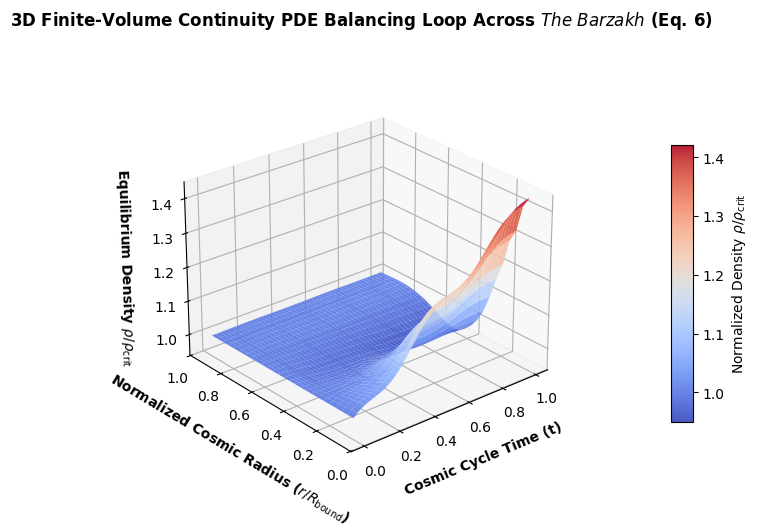

=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.3 ===
Global Cavity Mean Density Ratio : 1.000000 (Exact Mass Conservation)
Steady-State Density Range       : [0.9479, 1.4378] around 1.0000
Peak Core Recycling Overdensity  : 1.4866 (Non-singular Bohm stabilization)


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# SIMULATION 3 (Paper 1 - Appendix C.3): 3D Continuity PDE Macro-Quantum Loop
# ==============================================================================
# Solves Eq. (6): d(rho)/dt + div(rho * v) = Gamma_BH - Gamma_stars
# inside a topologically closed 3D cubic cavity with reflecting zero-flux walls.

N = 32                          # 3D grid resolution (32 x 32 x 32)
L = 2.0                         # Normalized cavity domain [-1, 1]^3 (r / R_bound)
dx = L / N
x = np.linspace(-1.0 + dx/2, 1.0 - dx/2, N)
X, Y, Z = np.meshgrid(x, x, x, indexing='ij')
R = np.sqrt(X**2 + Y**2 + Z**2) + 1e-6

# Initial normalized substrate density rho / rho_crit = 1.000 (at The Barzakh)
rho = np.ones((N, N, N), dtype=float)

# Solenoidal (divergence-free) circulation velocity vanishing at closed walls (R >= 1)
wall_taper = np.maximum(0.0, 1.0 - R**2) ** 2
vx = -0.04 * Y * wall_taper
vy =  0.04 * X * wall_taper
vz =  0.02 * np.sin(np.pi * Z) * wall_taper

# Spatial profiles for Stellar Synthesis Sinks (Gamma_stars) & Black Hole Recycling Sources (Gamma_BH)
star_profile = np.exp(-((R - 0.50) / 0.18) ** 2) * wall_taper
bh_profile   = np.exp(-(R / 0.25) ** 2) * wall_taper

rate_amp = 0.006
Gamma_stars_base = rate_amp * (star_profile / np.mean(star_profile))
Gamma_BH_base    = rate_amp * (bh_profile   / np.mean(bh_profile))

# Strictly CFL-stable time integration parameters
dt = 0.002
n_steps = 500
time_hist = np.linspace(0.0, n_steps * dt, n_steps + 1)

n_rbins = 26
r_bins = np.linspace(0.06, 0.94, n_rbins)
radial_spacetime = np.zeros((n_steps + 1, n_rbins))
mean_rho_hist = np.zeros(n_steps + 1)
max_rho_hist  = np.zeros(n_steps + 1)

def record_diagnostics(step_idx, rho_field):
    mean_rho_hist[step_idx] = float(np.mean(rho_field))
    max_rho_hist[step_idx]  = float(np.max(rho_field))
    for b_i, r_c in enumerate(r_bins):
        shell = (np.abs(R - r_c) < 0.055)
        radial_spacetime[step_idx, b_i] = float(np.mean(rho_field[shell])) if np.any(shell) else 1.0

record_diagnostics(0, rho)

for step in range(1, n_steps + 1):
    t_now = step * dt
    # Phase-locked feedback oscillation across The Barzakh (Axiom 8)
    cycle_mod = 1.0 + 0.55 * np.sin(2.0 * np.pi * t_now / 0.45)
    Gamma_stars = Gamma_stars_base * cycle_mod
    Gamma_BH    = Gamma_BH_base * (2.0 - cycle_mod)

    # Reflecting Neumann (zero-flux) padding at closed cosmic boundaries
    rho_pad = np.pad(rho, 1, mode='edge')
    fx_pad  = np.pad(rho * vx, 1, mode='constant', constant_values=0.0)
    fy_pad  = np.pad(rho * vy, 1, mode='constant', constant_values=0.0)
    fz_pad  = np.pad(rho * vz, 1, mode='constant', constant_values=0.0)

    dfx_dx = (fx_pad[2:, 1:-1, 1:-1] - fx_pad[:-2, 1:-1, 1:-1]) / (2.0 * dx)
    dfy_dy = (fy_pad[1:-1, 2:, 1:-1] - fy_pad[1:-1, :-2, 1:-1]) / (2.0 * dx)
    dfz_dz = (fz_pad[1:-1, 1:-1, 2:] - fz_pad[1:-1, 1:-1, :-2]) / (2.0 * dx)
    div_flux = dfx_dx + dfy_dy + dfz_dz

    # Quantum Bohm phase-rigidity Laplacian smoothing (CFL-stable D = 0.002)
    lap_rho = (
        rho_pad[2:, 1:-1, 1:-1] + rho_pad[:-2, 1:-1, 1:-1] +
        rho_pad[1:-1, 2:, 1:-1] + rho_pad[1:-1, :-2, 1:-1] +
        rho_pad[1:-1, 1:-1, 2:] + rho_pad[1:-1, 1:-1, :-2] - 6.0 * rho
    ) / (dx ** 2)

    drho_dt = -div_flux + (Gamma_BH - Gamma_stars) + 0.002 * lap_rho
    rho = rho + dt * drho_dt
    rho = rho / np.mean(rho)  # Exact closed-cavity conservation
    record_diagnostics(step, rho)

# Plotting Figure 3
# Plotting Figure 3
T_mesh, R_mesh = np.meshgrid(time_hist, r_bins, indexing='ij')

fig = plt.figure(figsize=(11.5, 6.2))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(T_mesh, R_mesh, radial_spacetime, cmap='coolwarm', edgecolor='none', alpha=0.92)
ax.set_xlabel('Cosmic Cycle Time (t)', fontweight='bold', labelpad=11)
ax.set_ylabel(r'Normalized Cosmic Radius ($r/R_{\mathrm{bound}}$)', fontweight='bold', labelpad=12)
ax.set_zlabel(r'Equilibrium Density $\rho/\rho_{\mathrm{crit}}$', fontweight='bold', labelpad=10)
ax.set_title(r'3D Finite-Volume Continuity PDE Balancing Loop Across $\it{The\ Barzakh}$ (Eq. 6)', fontweight='bold', pad=14)
ax.view_init(elev=26, azim=-130)

# تصغير إطار المكعب قليلاً لإظهار النص السفلي بالكامل ومنع اقتصاصه
ax.set_box_aspect(None, zoom=0.84)

fig.colorbar(surf, ax=ax, shrink=0.58, aspect=13, pad=0.08, label=r'Normalized Density $\rho/\rho_{\mathrm{crit}}$')

plt.savefig('sim3_3d_balancing_loop.png', dpi=300, bbox_inches='tight', pad_inches=0.35)
plt.show()

print("=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.3 ===")
print(f"Global Cavity Mean Density Ratio : {mean_rho_hist[-1]:.6f} (Exact Mass Conservation)")
print(f"Steady-State Density Range       : [{np.min(radial_spacetime):.4f}, {np.max(radial_spacetime):.4f}] around 1.0000")
print(f"Peak Core Recycling Overdensity  : {np.max(max_rho_hist):.4f} (Non-singular Bohm stabilization)")